<h4 style="margin:1; line-height:1.2; font-size:48px;">

Homework #2

<h4 style="margin:1; line-height:1.2; font-size:36px;">

Sergio Tambè 1000084729

<h4 style="margin:1; line-height:1.2; font-size:28px;">

The	goal	of	this	project	is	to	evaluate	the	financial	condition	of	a	company	–	the	one	
assigned	in	Homework	#1	–	based	on	metrics	stored	in	the	file	Symbol_Info.csv.	Students	
will	perform	the	analysis	by:	

• Extracting	and	cleaning	relevant	financial	data	from	Symbol_Info.csv

• Computing	key	financial	indicators	

• Comparing	the	company’s	results	with	peer	companies	(based	on	sector,	industry,	
country,	and	size)	

• Evaluating	the	company's	performance	on	specific	metrics	across	selected	subsets	
of	companies	

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# upload dataset
symbol_df = pd.read_csv("Symbols_info_modified.csv")
output_df = pd.read_csv("output.csv")

# Create a DataFrame containing	only the columns needed	for	the	analysis
required_columns = [
    'symbol', "company_name", 'sector', 'industry', 'country', 'market_cap', 'net_income', 'total_revenue',
    'return_on_assets', 'return_on_equity', 'profit_margins', 'pe_trailing', 'pe_forward',
    'earnings_growth', 'price_to_sales', 'price_to_book', 'revenue_growth',
    'debt_to_equity', 'free_cashflow'
]

# Using only the requested columns
df = symbol_df[required_columns].copy()

# If there are missing value for AXON (target company) in Symbol_df, use the data from Output_df
for col in required_columns:
    if df[col].isna().any():
        missing_symbols = df[df[col].isna()]['symbol']
        for sym in missing_symbols:
            val = output_df.loc[output_df['symbol'] == sym, col]
            if not val.empty:
                df.loc[df['symbol'] == sym, col] = val.values[0]


# Remove all companies (rows) where at least one required value	is missing
df_cleaned = df.dropna()
df_cleaned = df_cleaned[(df_cleaned != 0).all(axis=1)]

# Add new calculated columns
df_cleaned['net_profit_margin'] = df_cleaned['net_income'] / df_cleaned['total_revenue']
df_cleaned['peg_ratio'] = df_cleaned['pe_forward'] / df_cleaned['earnings_growth']

# Create final DataFrame with all metrics
metrics_df = df_cleaned[[
    'symbol', "company_name", 'sector', 'industry', 'country', 'market_cap',
    'net_profit_margin', 'return_on_assets', 'return_on_equity', 'profit_margins',
    'pe_trailing', 'pe_forward', 'peg_ratio', 'price_to_sales', 'price_to_book',
    'revenue_growth', 'earnings_growth',
    'debt_to_equity', 'free_cashflow'
]]

# Save dataframe that will be used 
metrics_df.to_csv("metrics_cleaned.csv", index=False)

<h4 style="margin:1; line-height:1.2; font-size:34px;">

Barplot

<h4 style="margin:1; line-height:1.2; font-size:26px;">

To evaluate the company's performance on specific parameters, we will create a series of **bar charts** to analyze 4 key financial metrics (Profitability, Valuation, Efficiency, and Financial Strength) compared to the top_5 of different groupings, by Sector, Industry, Country, and similar Market Cap.

Profitability (Indicator : "net_profit_margin") 
  AXON = 0.1490
  Average = 5897881.6492
  Median = 0.1001


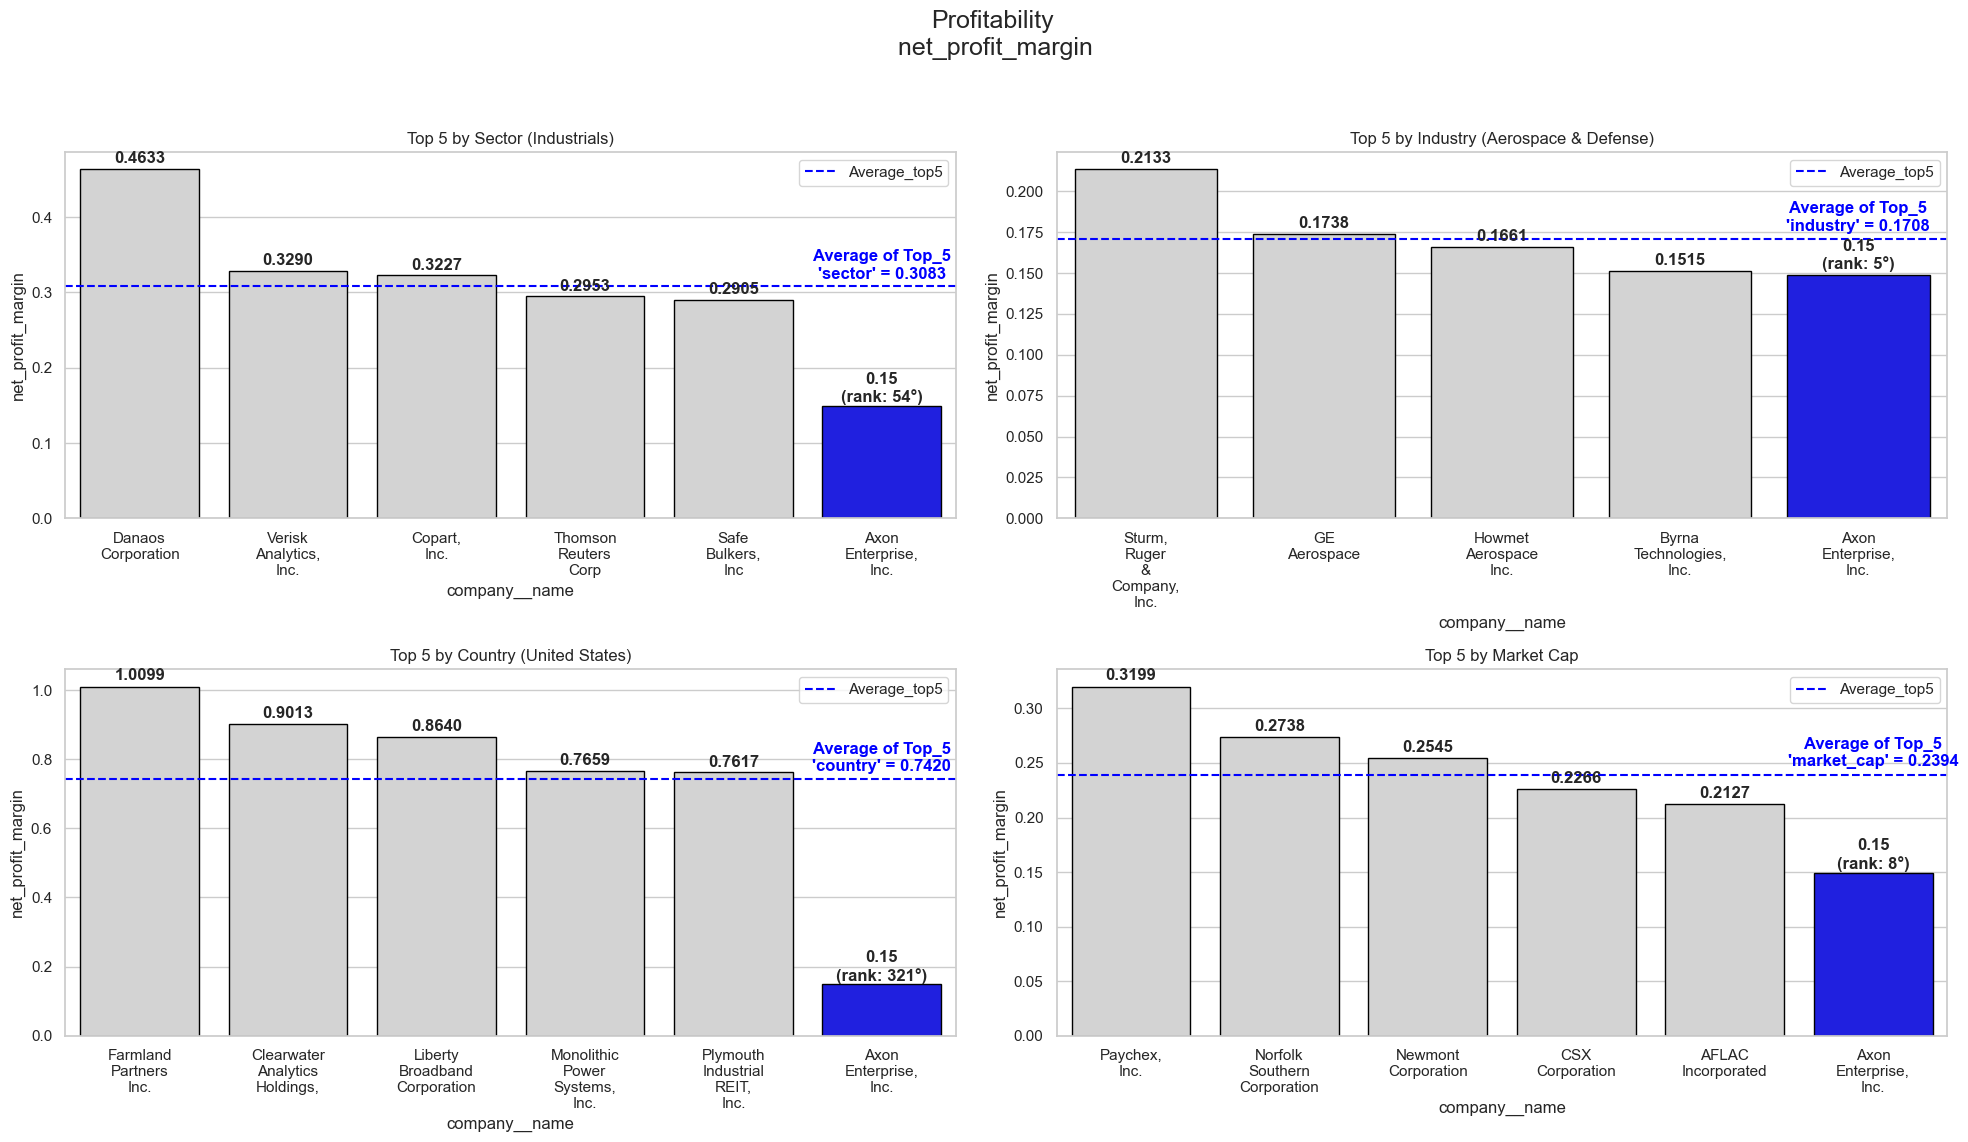

Valuation (Indicator : "peg_ratio") 
  AXON = -312.5129
  Average = -0.2942
  Median = 8.5793


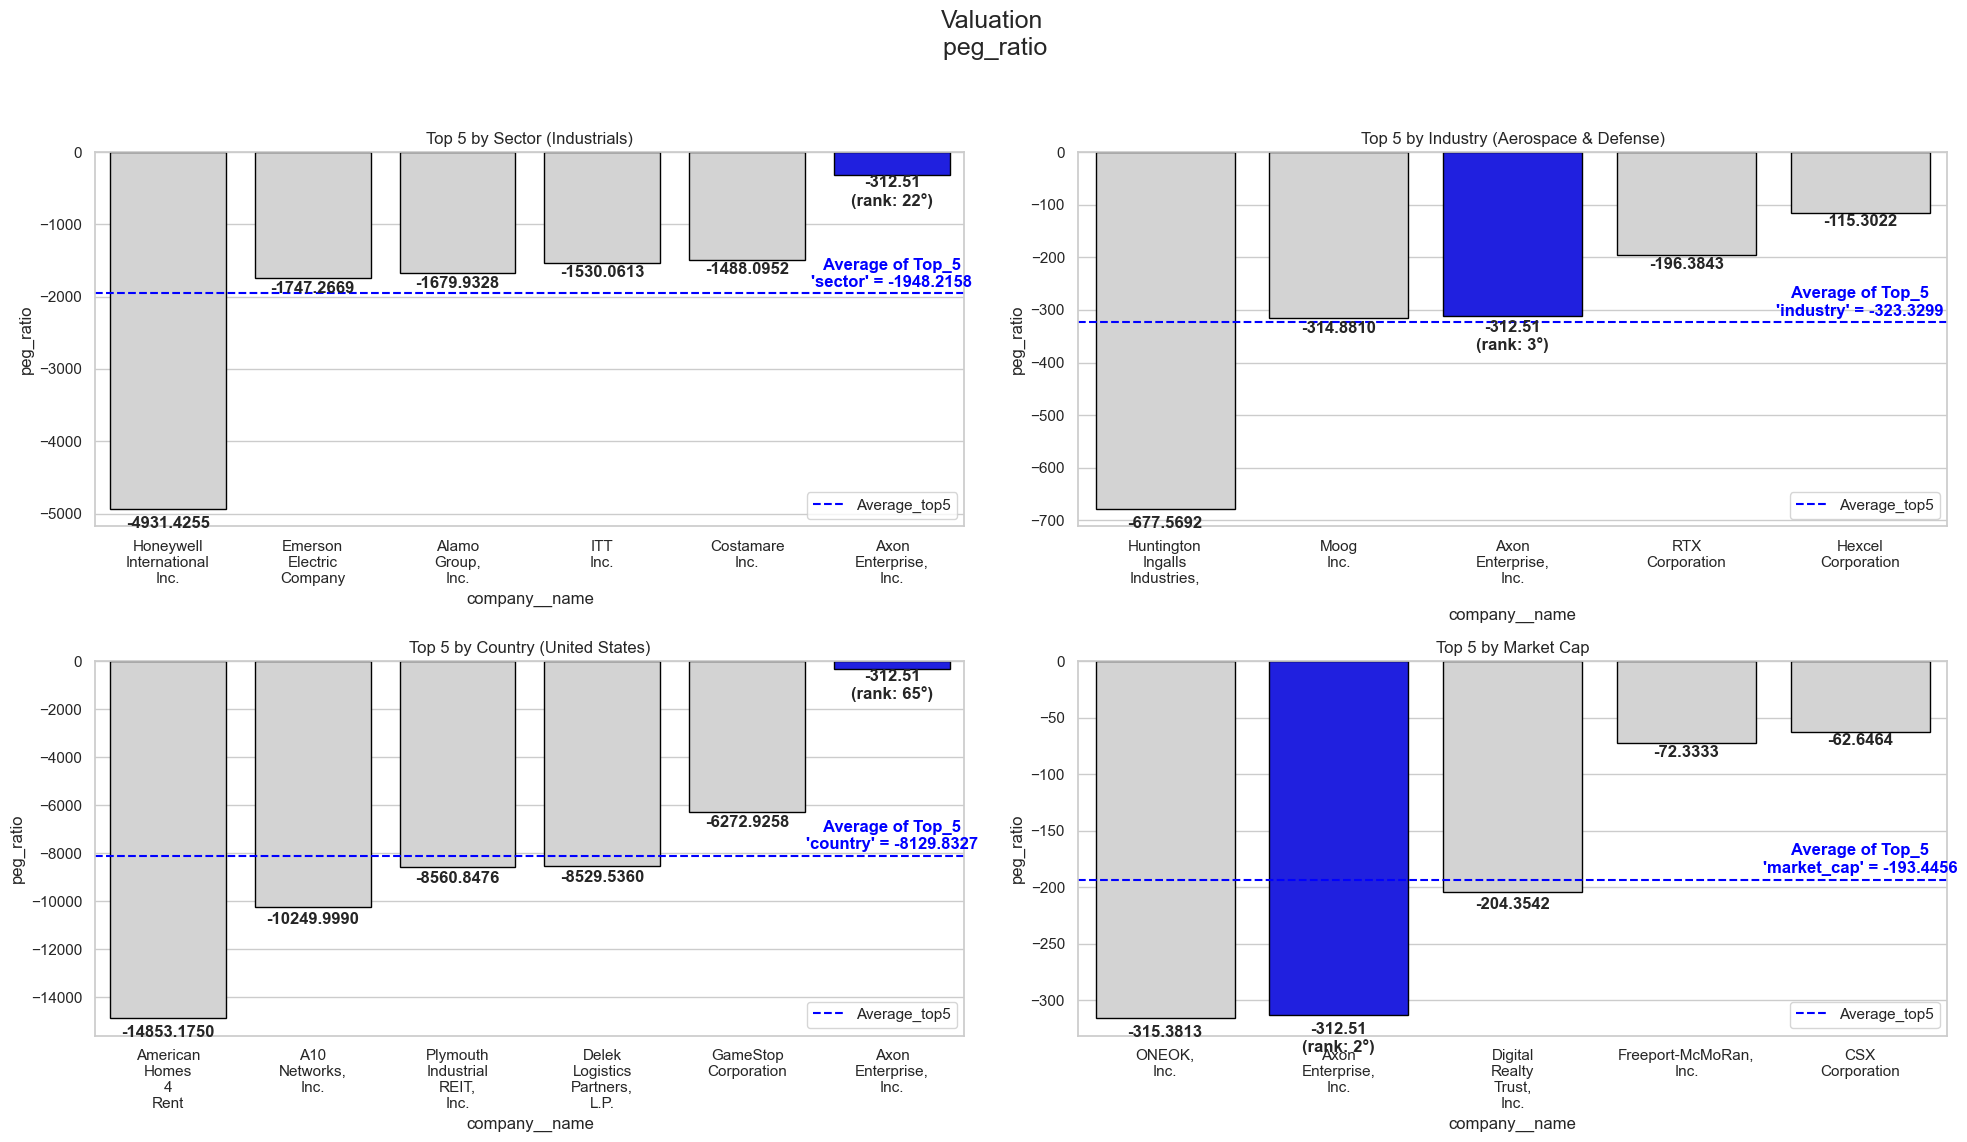

Efficiency (Indicator : "revenue_growth") 
  AXON = 0.3130
  Average = 0.0717
  Median = 0.0500


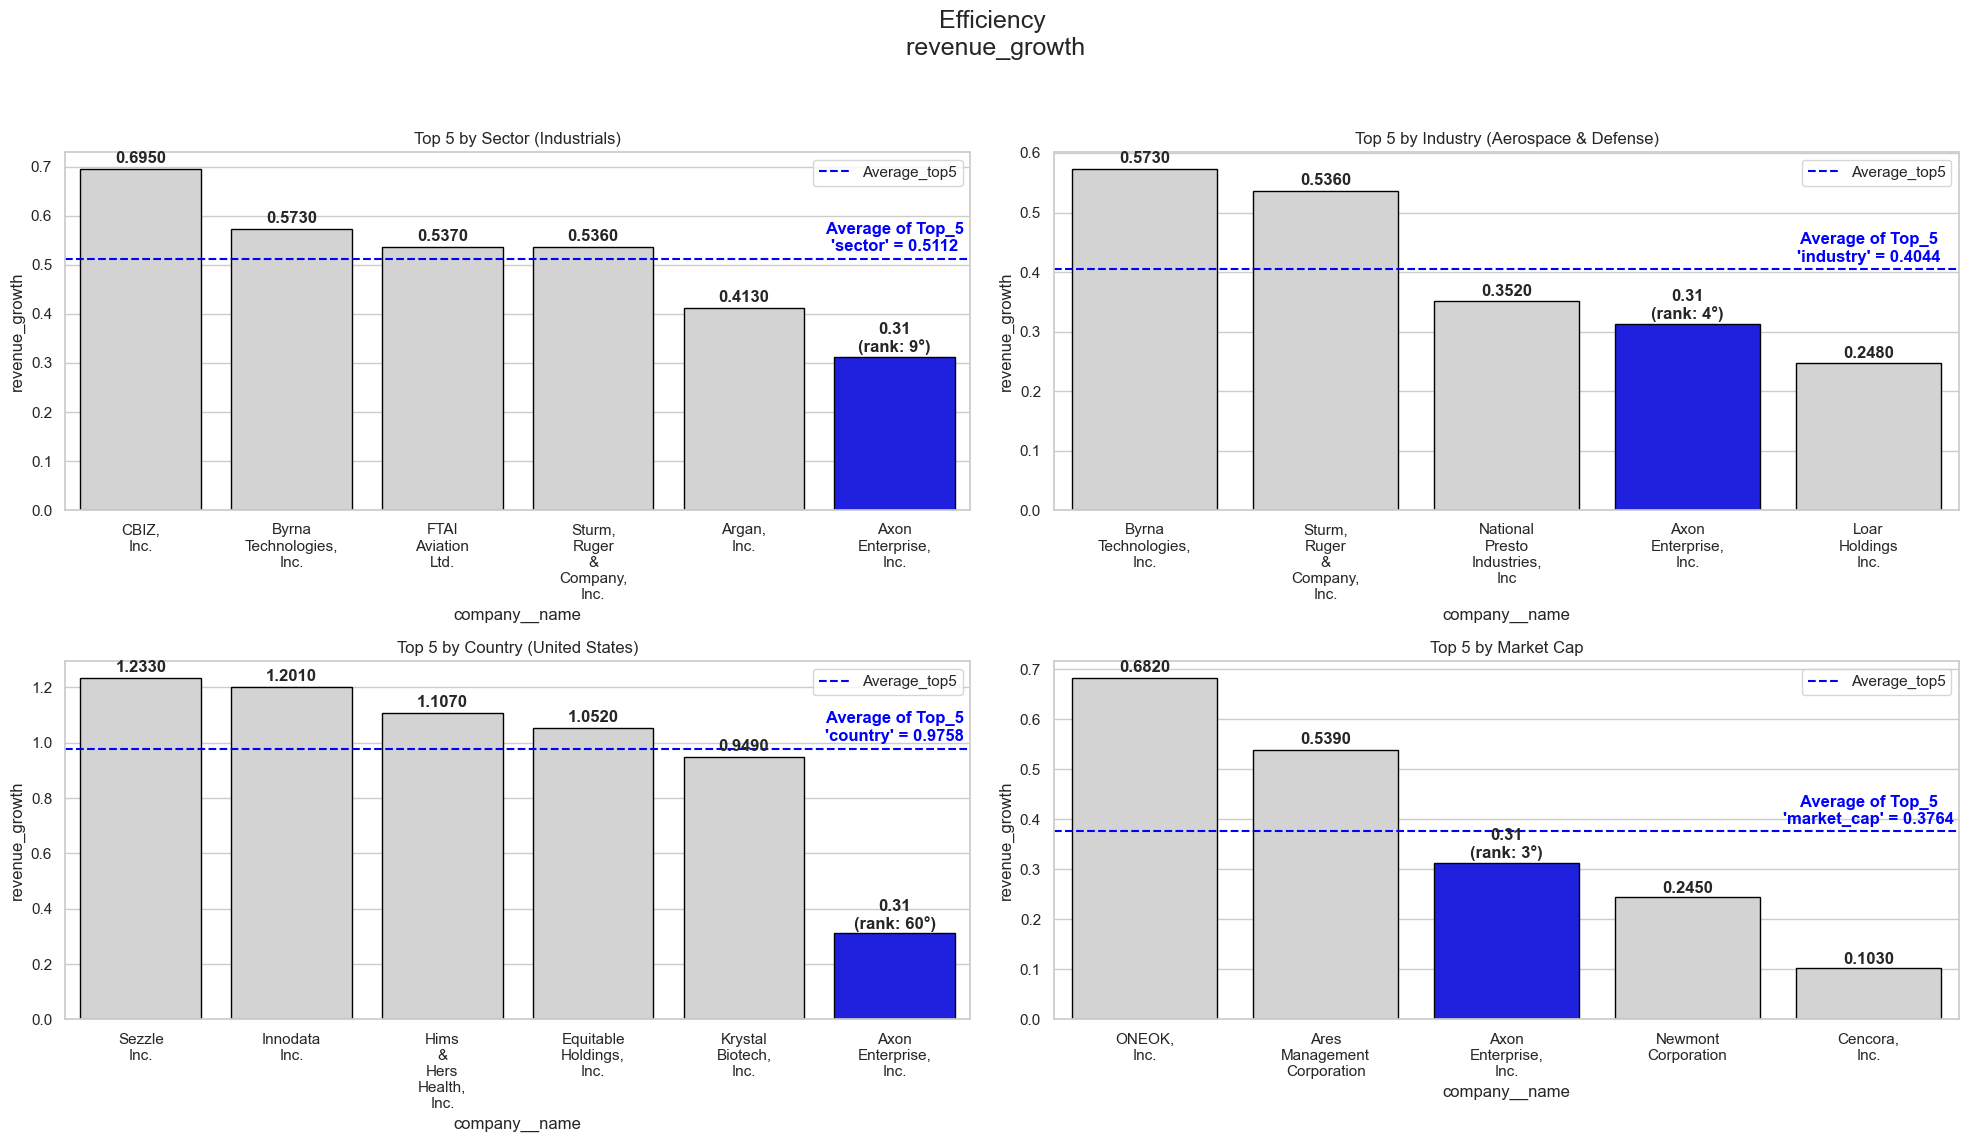

Financial Strength (Indicator : "debt_to_equity") 
  AXON = 80.0800
  Average = 127.8339
  Median = 64.0930


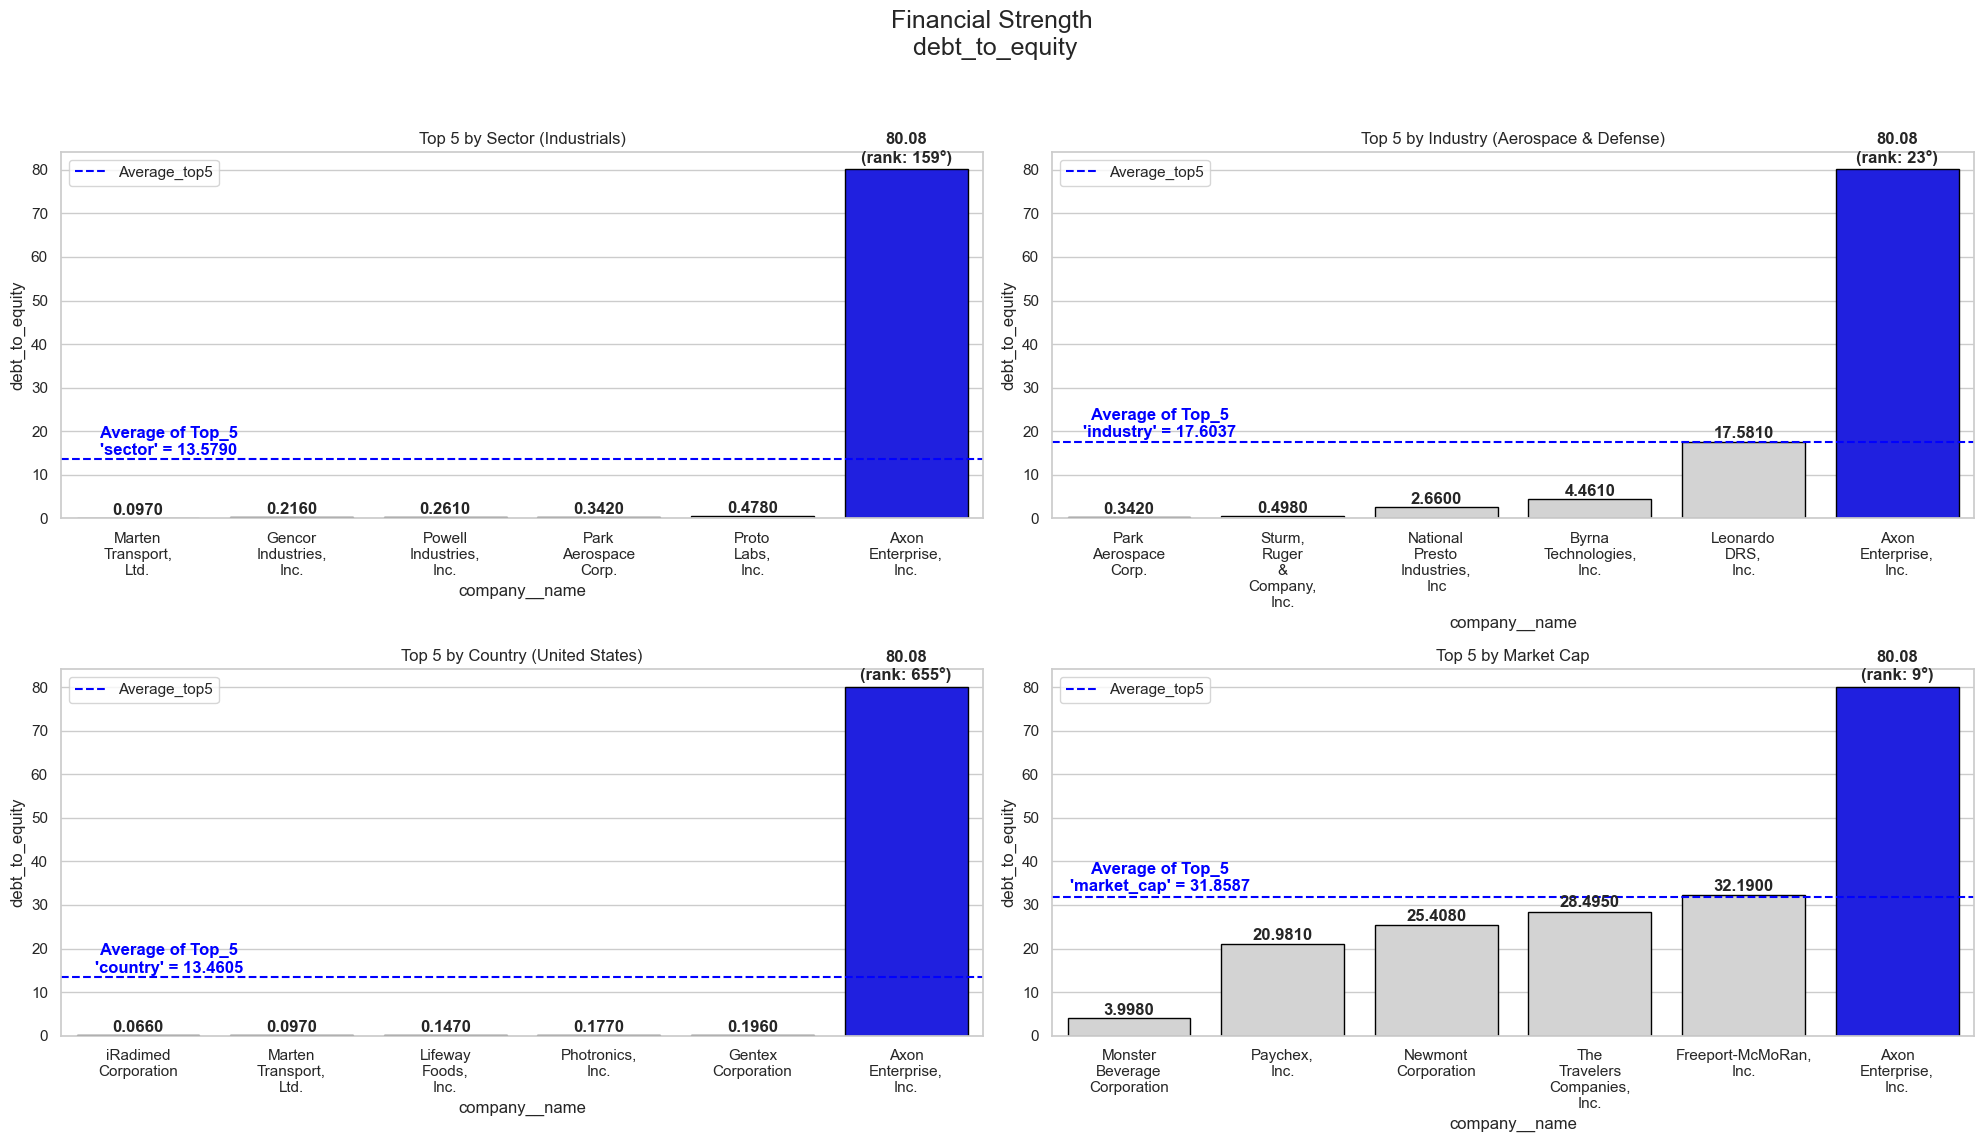

In [2]:
# Use our dataset
metrics_df = pd.read_csv("metrics_cleaned.csv")

# Impostazioni grafiche
sns.set(style="whitegrid")
plt.rcParams.update({'figure.figsize': (18, 12)})

# My Company
target_symbol = 'AXON'
axon_row = metrics_df[metrics_df['symbol'] == target_symbol]
if axon_row.empty:
    raise ValueError("AXON non è presente nel dataset. Verifica i filtri precedenti.")
target_company = axon_row.iloc[0]

# Metrics to compare
selected_metrics = {
    'Profitability': 'net_profit_margin',
    'Valuation': 'peg_ratio',
    'Efficiency': 'revenue_growth',
    'Financial Strength': 'debt_to_equity'
}
groupings = {
    'Sector': 'sector',
    'Industry': 'industry',
    'Country': 'country',
    'Market Cap': 'market_cap'
}

# Define a function to build the data useful for the barplots
def get_top5_df(metric_col, group_label, group_field):
    if group_label == 'Market Cap':
        metrics_df['mc_diff'] = abs(metrics_df['market_cap'] - target_company['market_cap'])
        group_df = metrics_df.nsmallest(15, 'mc_diff') # The 15 companies with the market_cap closest to the Axon's market_cap
    else:
        group_value = target_company[group_field]
        group_df = metrics_df[metrics_df[group_field] == group_value]

    group_df = group_df.dropna(subset=[metric_col])
    # For peg_ratio and debt_to_equity the Top_5 are the ones that have the less value
    ascending = True if metric_col in ['peg_ratio', 'debt_to_equity'] else False
    top_df = group_df.sort_values(by=metric_col, ascending=ascending).head(5) # Select the Top_5

    # Calculate the rank of target company
    group_df = group_df.sort_values(by=metric_col, ascending=ascending).reset_index(drop=True)
    target_position = None
    if target_symbol in group_df['symbol'].values:
        target_position = group_df[group_df['symbol'] == target_symbol].index[0] + 1  # 1-based

    # If AXON is not part of the top_5, add it
    if target_symbol not in top_df['symbol'].values:
        axon_row = metrics_df[(metrics_df['symbol'] == target_symbol) & (~metrics_df[metric_col].isna())]
        if not axon_row.empty:
            top_df = pd.concat([top_df, axon_row])

    # AXON in red, grey for the others
    palette = ['blue' if sym == target_symbol else 'lightgrey' for sym in top_df['symbol']]

    return top_df, palette, target_position


# Define a function to create the barplots, 4 barplots for each Metrics
def plot_metric_comparisons(metric_label, metric_col):
    # Calculate values: Average and Median of all companies
    average_a = metrics_df[metric_col].mean()
    median = metrics_df[metric_col].median()
    print(f'{metric_label} (Indicator : "{metric_col}") \n  AXON = {target_company[metric_col]:.4f}\n  Average = {average_a:.4f}\n  Median = {median:.4f}')
    fig, axes = plt.subplots(2, 2, figsize=(20, 12))
    fig.suptitle(f"{metric_label}\n {metric_col}", fontsize=18)
    axes = axes.flatten()

    for idx, (group_label, group_field) in enumerate(groupings.items()):
        top_df, palette, target_position = get_top5_df(metric_col, group_label, group_field)
        ax = axes[idx]
        y_col = metric_col

        # Barplot
        top_df['company__name'] = top_df['company_name'].str.replace(' ', '\n')
        sns.barplot(data=top_df, x= "company__name", y=y_col, hue='symbol', palette=palette, ax=ax, legend=False)

        ax.set_title(f"Top 5 by {group_label}" if group_label == 'Market Cap' else f"Top 5 by {group_label} ({target_company[group_field]})") # specify what is the group_label

        # Average of the Top_5 and put the line on the graphs
        average = top_df[metric_col].mean()
        ax.axhline(y= average, color='blue', linestyle='--', label='Average_top5')
        
        # Define the position of the line
        xpos = 0.2 if metric_label == "Financial Strength" else (5 if len(top_df)==6 else 4)
        offset = 0.02 * abs(average)
        ax.text(x=xpos,
                y=average + offset,
                s=f"Average of Top_5\n'{group_field}' = {average:.4f}",
                ha='center', va='bottom', fontsize=12, fontweight='bold', color='blue')
        

        # Put the value above the bars
        for bar, val, sym in zip(ax.patches, top_df[metric_col], top_df['symbol']):
            height = bar.get_height()
            x = bar.get_x() + bar.get_width() / 2
            # Put the rank on the Axon's bar, to evidence the difference with the Top_5
            label = f"{val:.2f}\n(rank: {target_position}°)" if sym == target_symbol else f"{val:.4f}"

            # For Valuation, we have negative values, so put the value below the bars
            if metric_label == "Valuation":
                y = height - 0.02 * abs(height)
                va = 'top'
            else:
                y = height + 0.01 * abs(height)
                va = 'bottom'
            ax.text(x, y, label, ha='center', va=va, fontsize=12, fontweight='bold')

        for bar in ax.patches:
            bar.set_edgecolor('black')

        ax.legend()

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Repeat the function (Generate the 4 barplots) for each metric
for cat_label, metric_col in selected_metrics.items():
    plot_metric_comparisons(cat_label, metric_col)

<h4 style="margin:1; line-height:1.2; font-size:26px;">

By looking at the graphs, we can say:

<h4 style="margin:1; line-height:1.2; font-size:34px;">

1. Profitability – net_profit_margin

<h4 style="margin:1; line-height:1.2; font-size:26px;">

AXON demonstrates **average profitability** within its sector (Industrials, ranked **54th**), and a strong position within its industry (Aerospace & Defence, **5th**). However, it ranks **quite low** at the national level (**321st** in the United States), likely due to the presence of many highly profitable firms. Among the 15 companies with the **most similar market cap**, it ranks **8th**, slightly **below average**.
Conclusion: AXON is **moderately competitive** within its niche but **struggles** to stand out **nationally** and among similar-sized peers. There’s room to improve profitability.

<h4 style="margin:1; line-height:1.2; font-size:34px;">

2. Valuation – peg_ratio

<h4 style="margin:1; line-height:1.2; font-size:26px;">

AXON shows a very strong valuation profile: **2nd** among market cap peers and **3rd** in its industry. It also performs well within its sector (**22nd**) and at the national level (**65th**), suggesting that it is fairly valued relative to **expected growth**.
Conclusion: AXON appears to be **attractively** valued, which may indicate **market confidence** in its fundamentals or highlight a compelling investment opportunity.

<h4 style="margin:1; line-height:1.2; font-size:34px;">

3. Growth – revenue_growth

<h4 style="margin:1; line-height:1.2; font-size:26px;">

The company shows **strong growth performance**, ranking **9th** in its sector, **4th** in its industry, and **3rd** among market cap peers. Even on a national level (**60th** in the U.S.), the ranking is solid given the size of the market.
Conclusion: AXON is clearly a **high-growth company**, outperforming many of its peers across all groups considered.

<h4 style="margin:1; line-height:1.2; font-size:34px;">

4. Financial Strength – debt_to_equity

<h4 style="margin:1; line-height:1.2; font-size:26px;">

The charts related to the debt_to_equity metric show wide and uneven value distributions.
For this reason, we will apply a **logarithmic** transformation **log(1+x)** to the values to enable a more **interpretable** and **visually** balanced comparison.



Financial Strength (Indicator : "debt_to_equity") 
  AXON = 80.0800
  Average = 127.8339
  Median = 64.0930


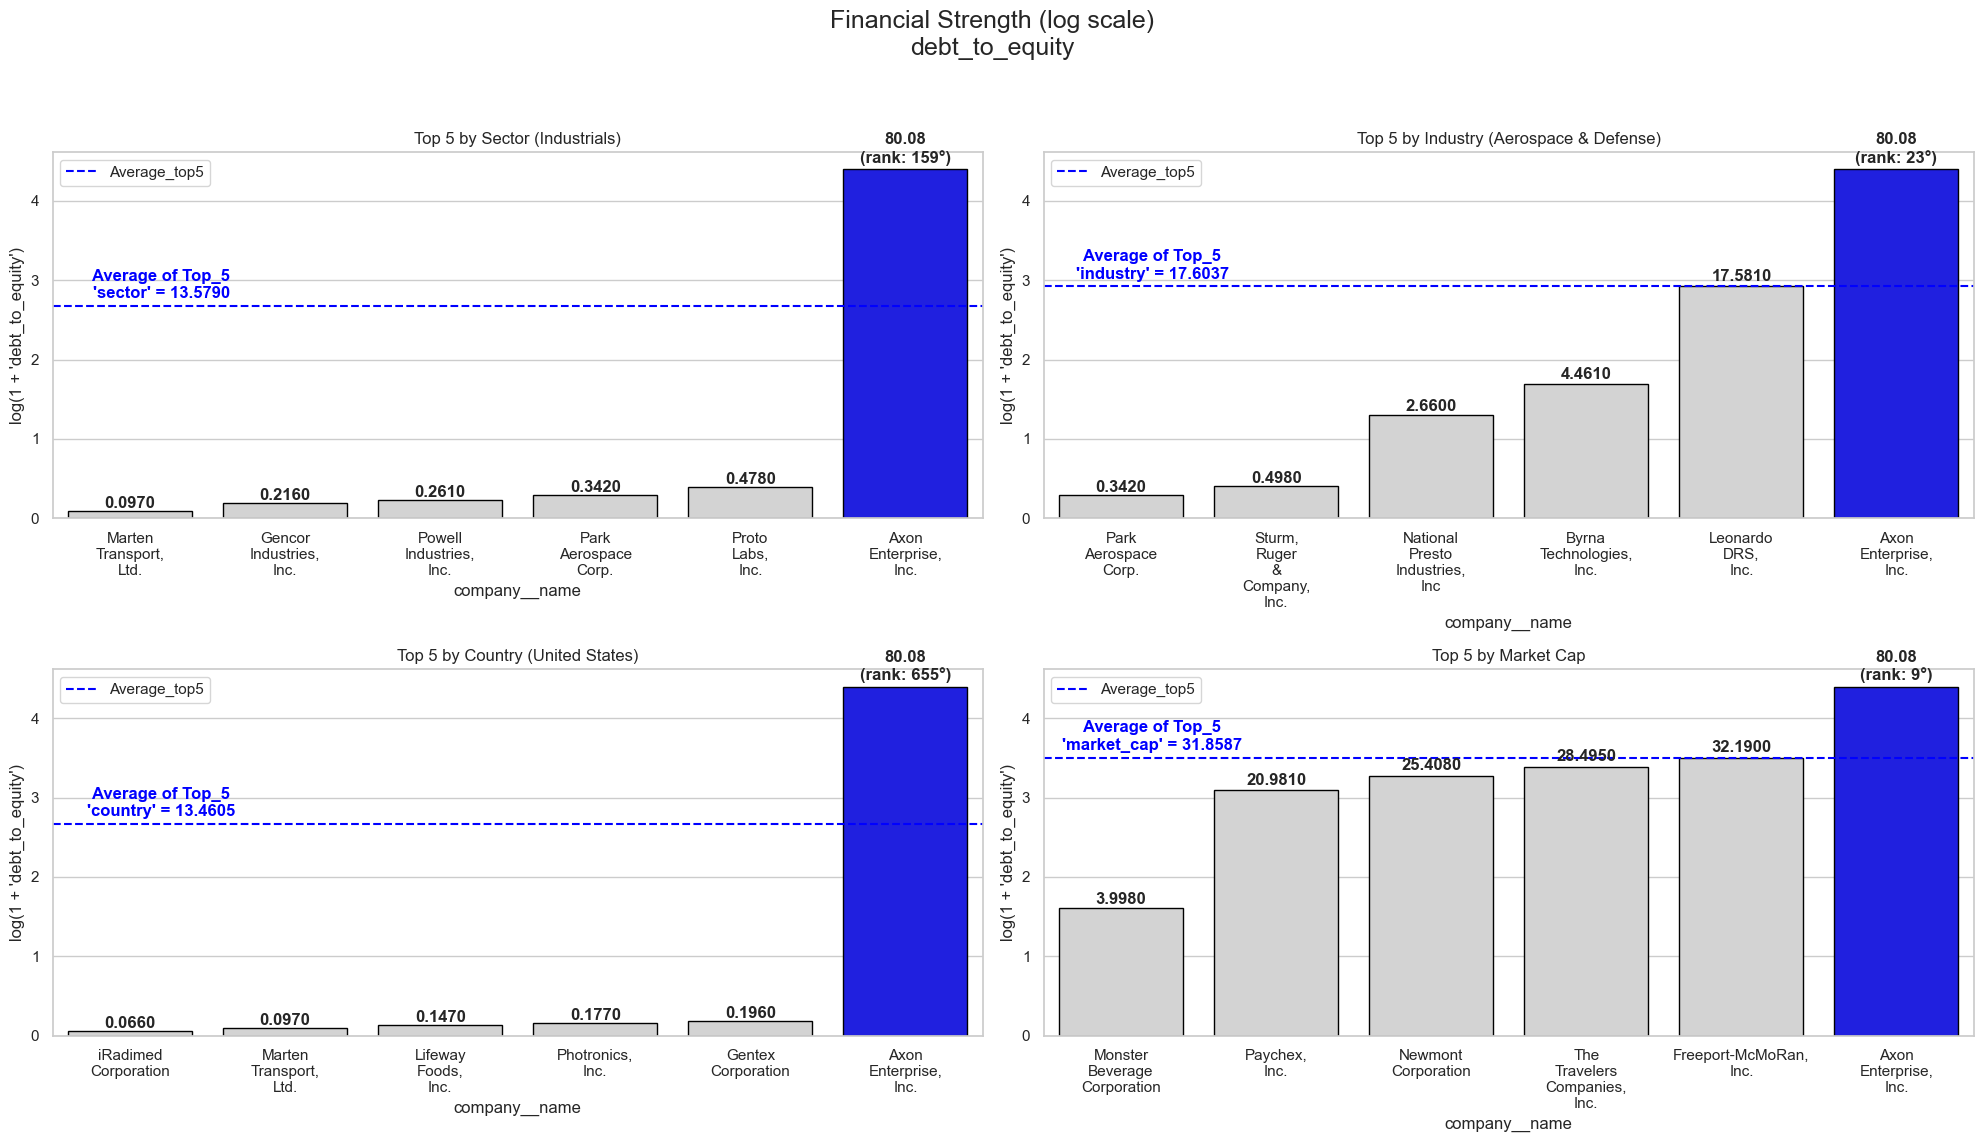

In [3]:
# Function that make barplots for Financial Strength
def plot_financial_strength_log():
    metric_label = 'Financial Strength'
    metric_col = 'debt_to_equity'
    # Average and Median of all companies
    average_a = metrics_df[metric_col].mean()
    median = metrics_df[metric_col].median()
    print(f'{metric_label} (Indicator : "{metric_col}") \n  AXON = {target_company[metric_col]:.4f}\n  Average = {average_a:.4f}\n  Median = {median:.4f}')

    fig, axes = plt.subplots(2, 2, figsize=(20, 12))
    fig.suptitle(f"{metric_label} (log scale)\n{metric_col}", fontsize=18)
    axes = axes.flatten()

    for idx, (group_label, group_field) in enumerate(groupings.items()):
        top_df, palette, target_position = get_top5_df(metric_col, group_label, group_field)
        ax = axes[idx]

        top_df = top_df.copy()
        # Add the logaritm value using the np.log1p() function
        top_df['log_metric'] = np.log1p(top_df[metric_col])  # In this situation we can use also log(x) because we don't have 0 values, but in general it's better to use log(1+x)
        y_col = 'log_metric'

        top_df['company__name'] = top_df['company_name'].str.replace(' ', '\n')
        sns.barplot(data=top_df, x="company__name", y=y_col, hue='symbol', palette=palette, ax=ax, legend=False)

        ax.set_title(f"Top 5 by {group_label}" if group_label == 'Market Cap' else f"Top 5 by {group_label} ({target_company[group_field]})")
        
        # Average of Top_5
        avg_original = top_df[metric_col].mean() # original average to write on the graph
        avg_log = np.log1p(avg_original)         # average of logaritm that we will use top define the position of the line '--'
        ax.axhline(y=avg_log, color='blue', linestyle='--', label='Average_top5')

        xpos = 0.2
        offset = 0.02 * abs(avg_log)
        
        # write the Average value on the line in the graph
        ax.text(x=xpos,
                y=avg_log + offset,
                s=f"Average of Top_5\n'{group_field}' = {avg_original:.4f}",
                ha='center', va='bottom', fontsize=12, fontweight='bold', color='blue')

        for bar, val, sym in zip(ax.patches, top_df[metric_col], top_df['symbol']):
            height = bar.get_height()
            x = bar.get_x() + bar.get_width() / 2
            # Put the Axon's rank on the bar
            label = f"{val:.2f}\n(rank: {target_position}°)" if sym == target_symbol else f"{val:.4f}"
            y = height + 0.01 * abs(height)
            ax.text(x, y, label, ha='center', va='bottom', fontsize=12, fontweight='bold')

        for bar in ax.patches:
            bar.set_edgecolor('black')

        # Specify that we use the logaritm
        ax.set_ylabel(f"log(1 + '{metric_col}')")
        ax.legend()

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# Make the graphs
plot_financial_strength_log()


<h4 style="margin:1; line-height:1.2; font-size:34px;">

4. Financial Strength – debt_to_equity

<h4 style="margin:1; line-height:1.2; font-size:26px;">

After applying the logarithmic transformation, AXON’s position relative to its peers becomes much clearer:
- **159th** within its sector (Industrials)
- **23rd** within its industry (Aerospace & Defence)
- **655th** in its country (United States)
- **9th** among the 15 companies with the most similar market capitalization

These rankings show that AXON has one of the **highest debt-to-equity ratios** in its comparison groups, particularly at the sector and national levels.
This indicates a **heavily leveraged** capital structure, which could represent a **significant weakness** in periods of economic **uncertainty** or rising interest rates.
In conclusion, financial strength appears to be the company’s main structural weakness, and it may **benefit** from a more balanced capital allocation to support long-term sustainability.

<h4 style="margin:1; line-height:1.2; font-size:34px;">

Overall Summary

<h4 style="margin:1; line-height:1.2; font-size:26px;">

AXON is a growing company, favorably valued by the market, and competitively positioned in terms of profitability and revenue growth within its industry. However, its high leverage stands out as a vulnerability. The company has strong potential, but improving its financial stability should be a key strategic focus moving forward.

In [4]:
#########################################################################################à

<h4 style="margin:1; line-height:1.2; font-size:34px;">
Scatterplot

<h4 style="margin:1; line-height:1.2; font-size:26px;">

To better understand **AXON’s positioning** relative to comparable companies, we will create a series of **scatterplots** using key pairs of financial metrics. This visual technique makes it easier to detect **outliers** and identify **overall positioning trends**. The analysis will be initially conducted using a **±25% range** from **AXON’s metrics**.

count    1285.000000
mean       19.842380
std        85.396301
min     -2873.000000
25%        11.257029
50%        17.084017
75%        24.546474
max       539.333400
Name: pe_forward, dtype: float64 

count    1285.000000
mean        0.221940
std         0.365555
min        -0.004280
25%         0.085090
50%         0.139320
75%         0.244040
max         5.423920
Name: return_on_equity, dtype: float64 

AXON values:
pe_forward = 117.504845
return_on_equity = 0.15166001


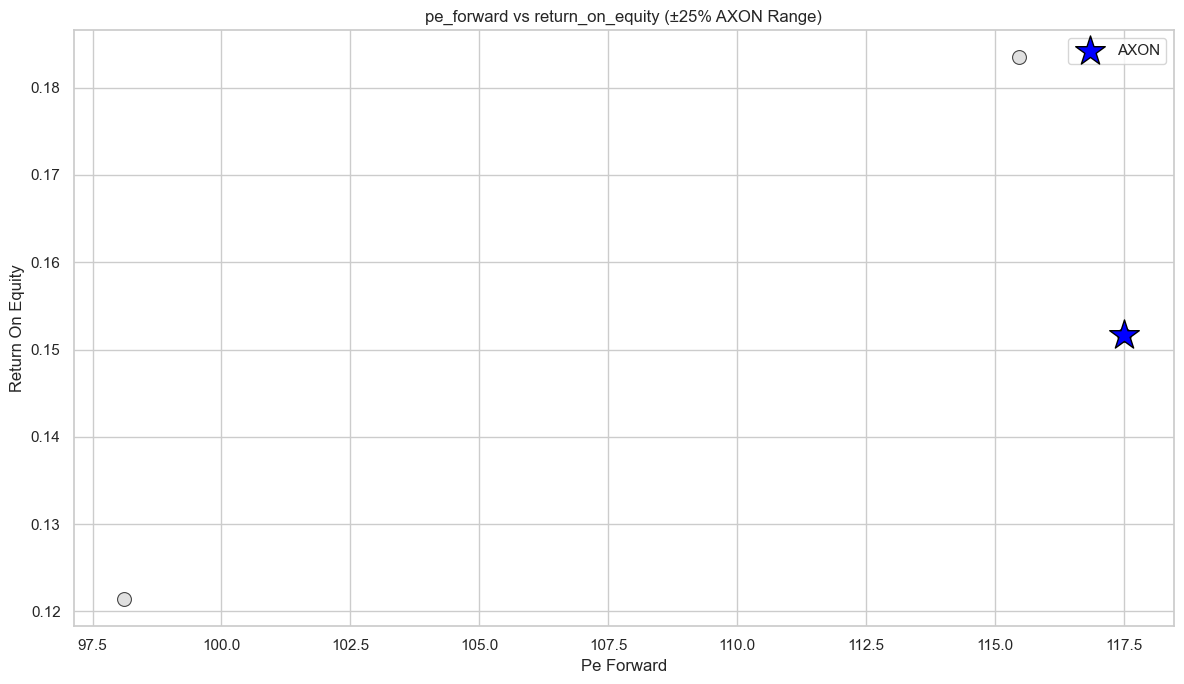

count    1285.000000
mean        3.764573
std        14.188942
min         0.000128
25%         0.965659
50%         2.008462
75%         4.140519
max       483.975400
Name: price_to_sales, dtype: float64 

count    1.285000e+03
mean     5.897882e+06
std      2.114207e+08
min      1.170175e-03
25%      5.353922e-02
50%      1.000752e-01
75%      1.697749e-01
max      7.578778e+09
Name: net_profit_margin, dtype: float64 

AXON values:
price_to_sales = 25.474993
net_profit_margin = 0.1489753333491252


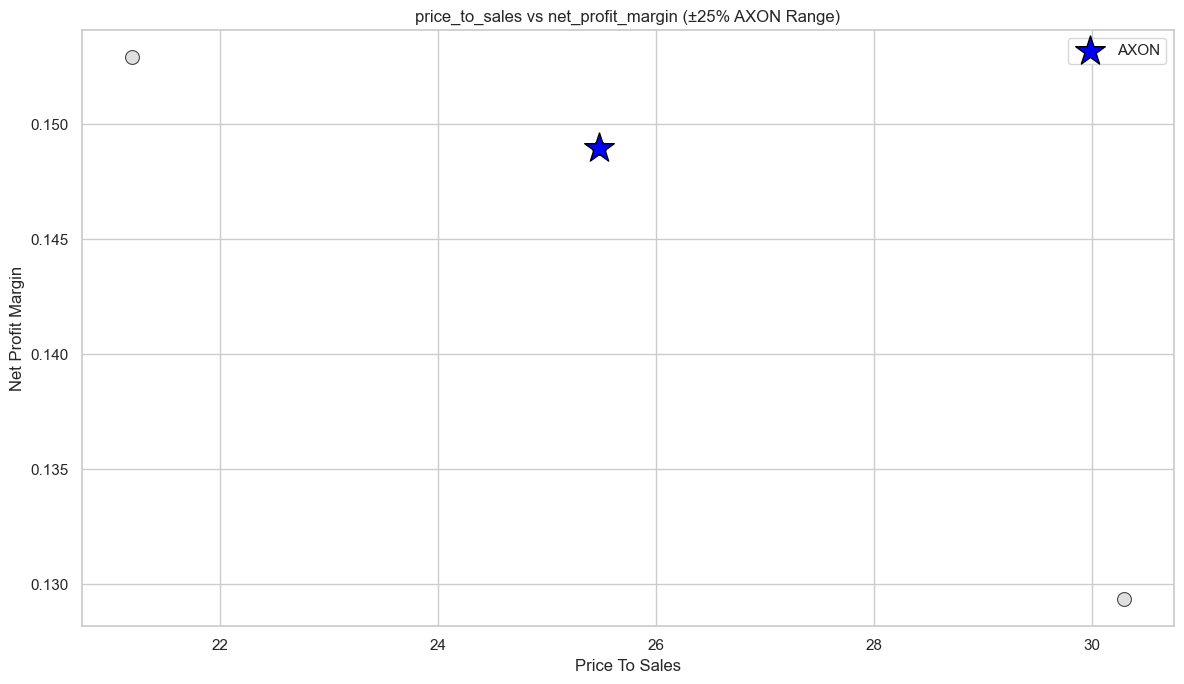

count    1285.000000
mean        0.071723
std         0.163043
min        -0.504000
25%        -0.014000
50%         0.050000
75%         0.120000
max         1.544000
Name: revenue_growth, dtype: float64 

count    1285.000000
mean        0.064241
std         0.044568
min        -0.004040
25%         0.035280
50%         0.055500
75%         0.081200
max         0.574170
Name: return_on_assets, dtype: float64 

AXON values:
revenue_growth = 0.313
return_on_assets = 0.00677


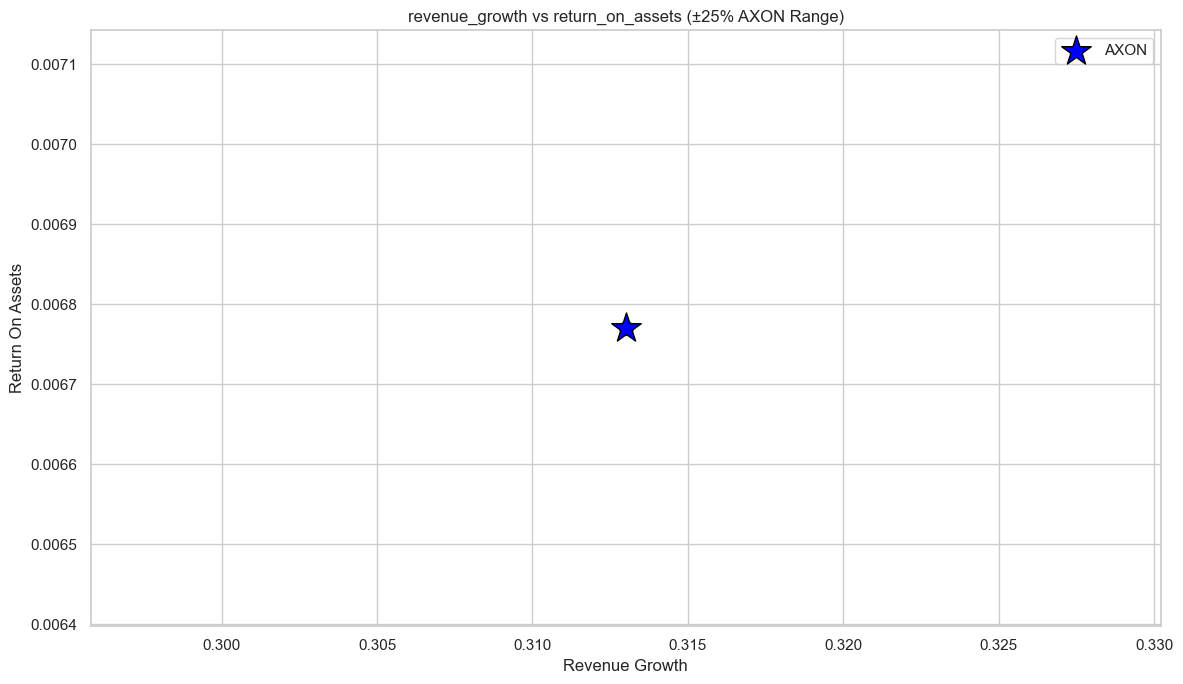

count     1285.000000
mean       127.833949
std        447.115510
min          0.066000
25%         25.920000
50%         64.093000
75%        125.441000
max      12986.719000
Name: debt_to_equity, dtype: float64 

count    1285.000000
mean        0.221940
std         0.365555
min        -0.004280
25%         0.085090
50%         0.139320
75%         0.244040
max         5.423920
Name: return_on_equity, dtype: float64 

AXON values:
debt_to_equity = 80.08
return_on_equity = 0.15166001


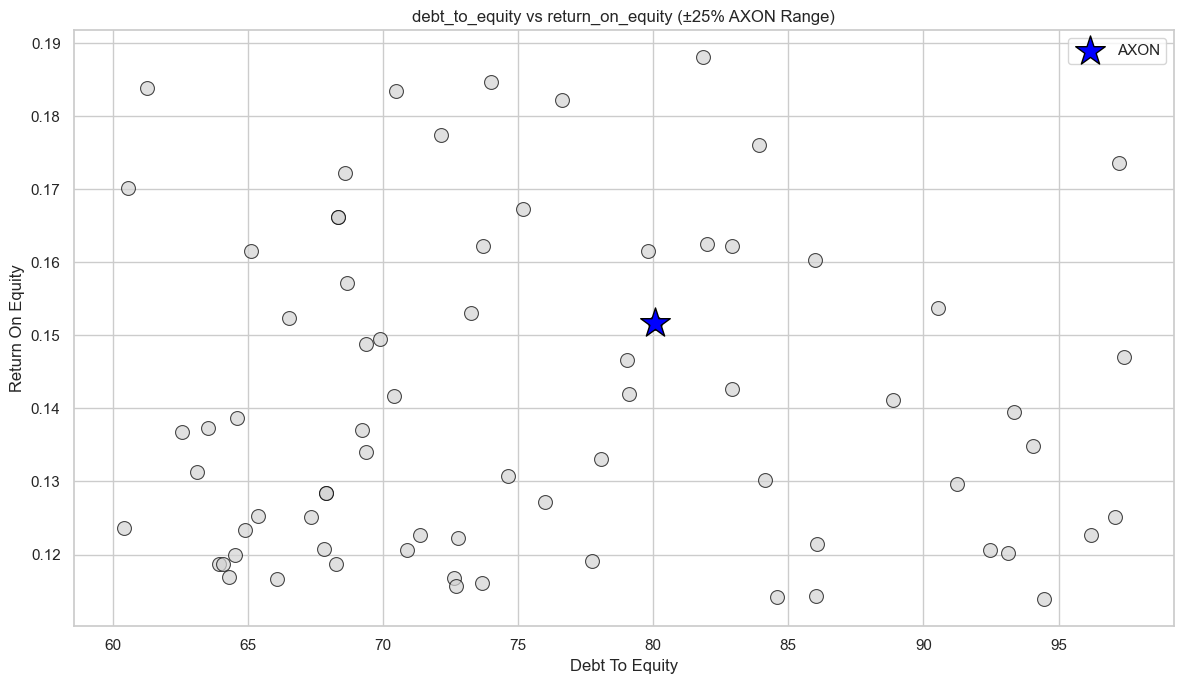

In [5]:
# Use the dataframe created
metrics_df = pd.read_csv("metrics_cleaned.csv")

target_symbol = 'AXON'
target_company = metrics_df[metrics_df['symbol'] == target_symbol]
target_company = target_company.iloc[0] 

# Metric ombinations list chosen
scatter_combinations = [
    ('pe_forward', 'return_on_equity'),
    ('price_to_sales','net_profit_margin'),
    ('revenue_growth', 'return_on_assets'),
    ('debt_to_equity','return_on_equity')
]

# Define the function to generate the scatterplot
def plot_scatter(metric_x, metric_y):
    x_val = target_company[metric_x]
    y_val = target_company[metric_y]

    # Range ±25%
    x_low, x_high = x_val * 0.75, x_val * 1.25
    y_low, y_high = y_val * 0.75, y_val * 1.25

    # dataset filtered in according to the Range ±25%
    filtered_df = metrics_df[
        metrics_df[metric_x].between(x_low, x_high) &
        metrics_df[metric_y].between(y_low, y_high)
    ]

    # Scatter plot where all companied are represented by grey point
    plt.figure(figsize=(12, 7))
    sns.scatterplot(
        data=filtered_df,
        x=metric_x,
        y=metric_y,
        color='lightgrey',
        alpha=0.7,
        s=100,
        edgecolor='black'
    )

    # Evidence AXON with a big red star
    plt.scatter(
        x_val, y_val,
        color='blue',
        s=500,
        marker='*',
        label='AXON',
        edgecolor='black',
        zorder=5
    )

    plt.title(f"{metric_x} vs {metric_y} (±25% AXON Range)")
    plt.xlabel(metric_x.replace('_', ' ').title())
    plt.ylabel(metric_y.replace('_', ' ').title())
    plt.legend()
    plt.tight_layout()
    plt.show()

# Generate the scatter plot requested and the variable description
for i, (metric_x, metric_y) in enumerate(scatter_combinations):
    print(metrics_df[metric_x].describe(),'\n')
    print(metrics_df[metric_y].describe(),'\n')
    print("AXON values:")
    print(f"{metric_x} = {target_company[metric_x]}")
    print(f"{metric_y} = {target_company[metric_y]}")
    plot_scatter(metric_x, metric_y)



<h4 style="margin:1; line-height:1.2; font-size:26px;">

In the first set of scatterplots using the **±25% range**, AXON clearly stands out as an **outlier** in the first three comparisons:
- **PE Forward** vs **Return on Equity**
- **Price to Sales** vs **Net Profit Margin**
- **Revenue Growth** vs **Return on Assets**

In these plots, AXON appears as one of the only companies visible, sometimes the **sole point** or accompanied by just one or two others. This indicates that **AXON’s metrics are significantly different** from its peers, placing it in areas of the chart where few companies operate — a sign of strong or atypical performance.
We can notice it also from the description of the variables. AXON has values that are **very different from the mean and median**.

In contrast, in the scatterplot where there is the comparison:
- **Debt to Equity** vs **Return on Equity**

The scenario is different: many companies are present, and AXON is positioned slightly below the **average** of the group. This suggests that, in terms of financial leverage and equity efficiency, AXON’s profile is more **aligned** with the broader industry, showing **no distinct outlier** behavior.
We can notice it also from the description of the variable. In fact, AXON has values **very close to the mean and the median**.


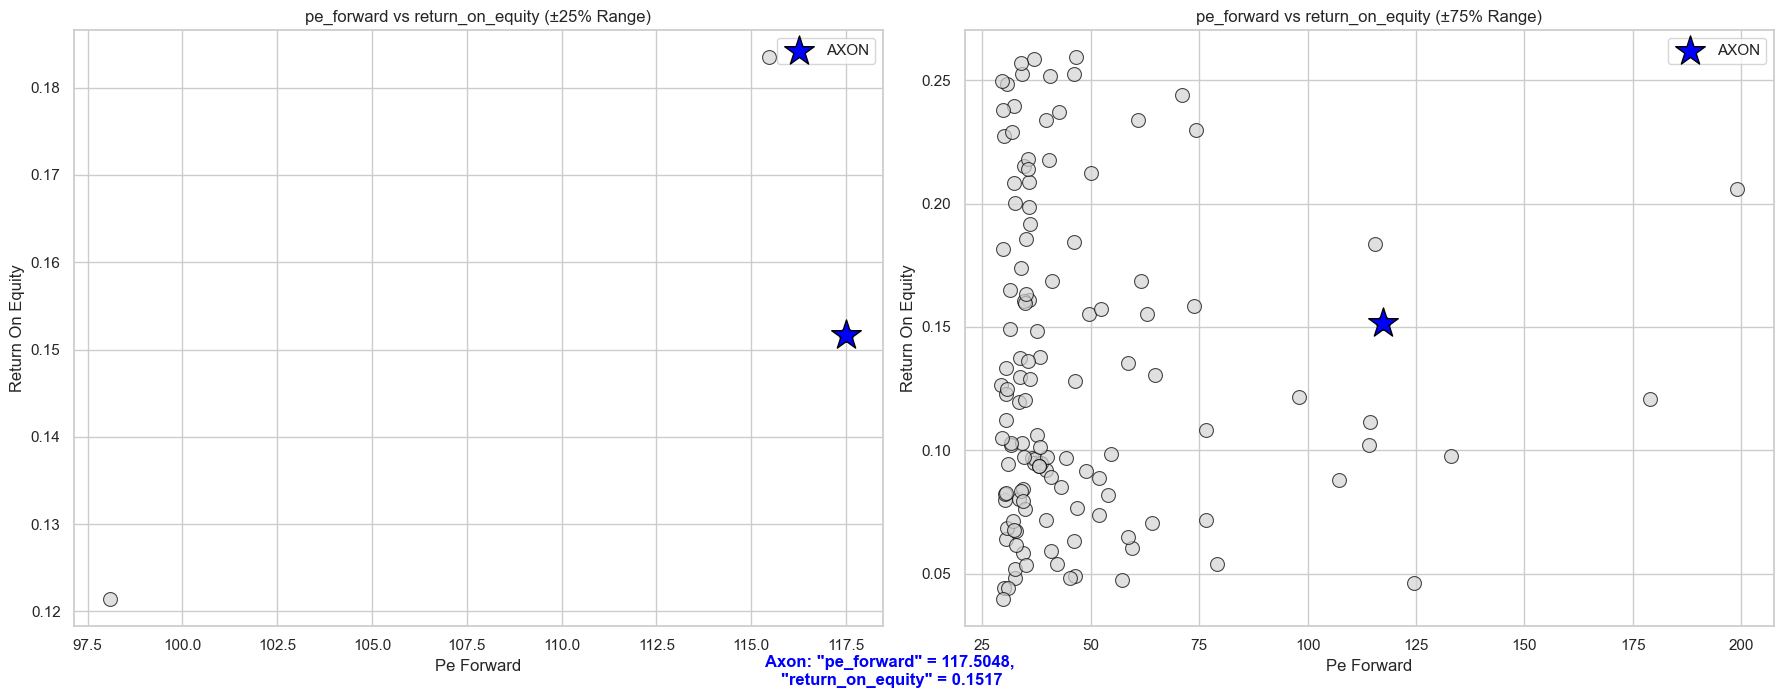

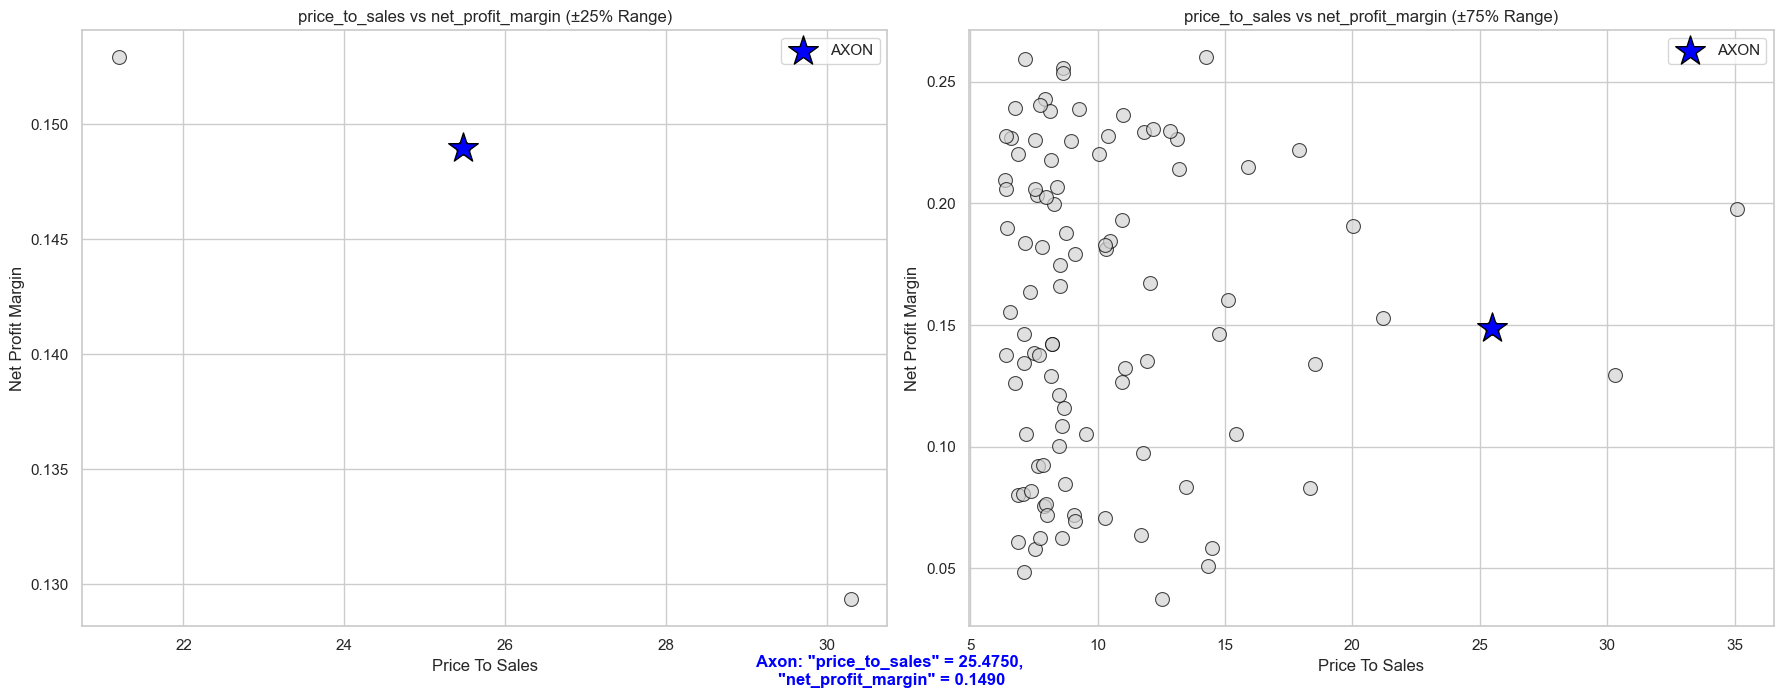

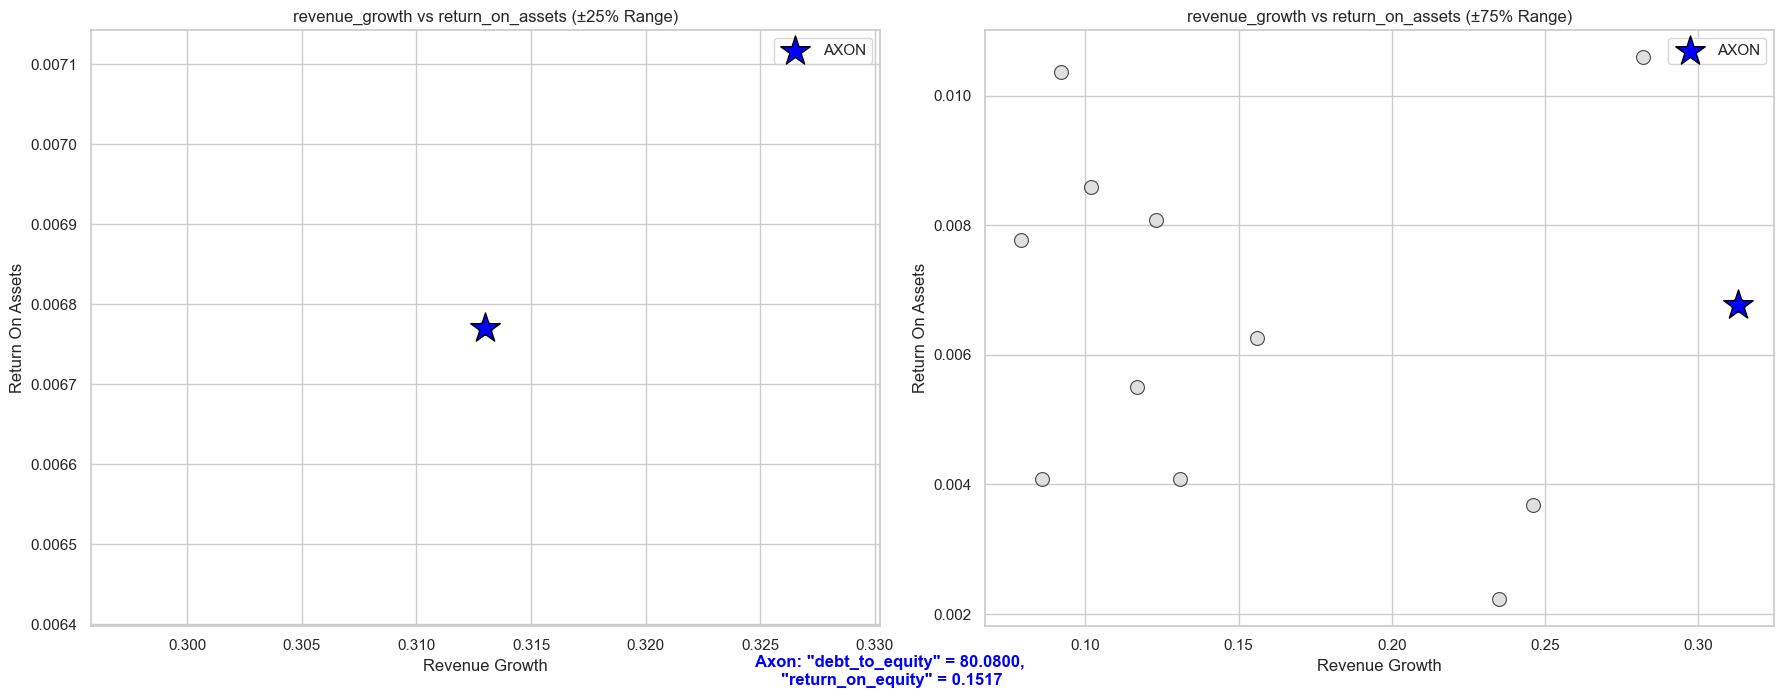

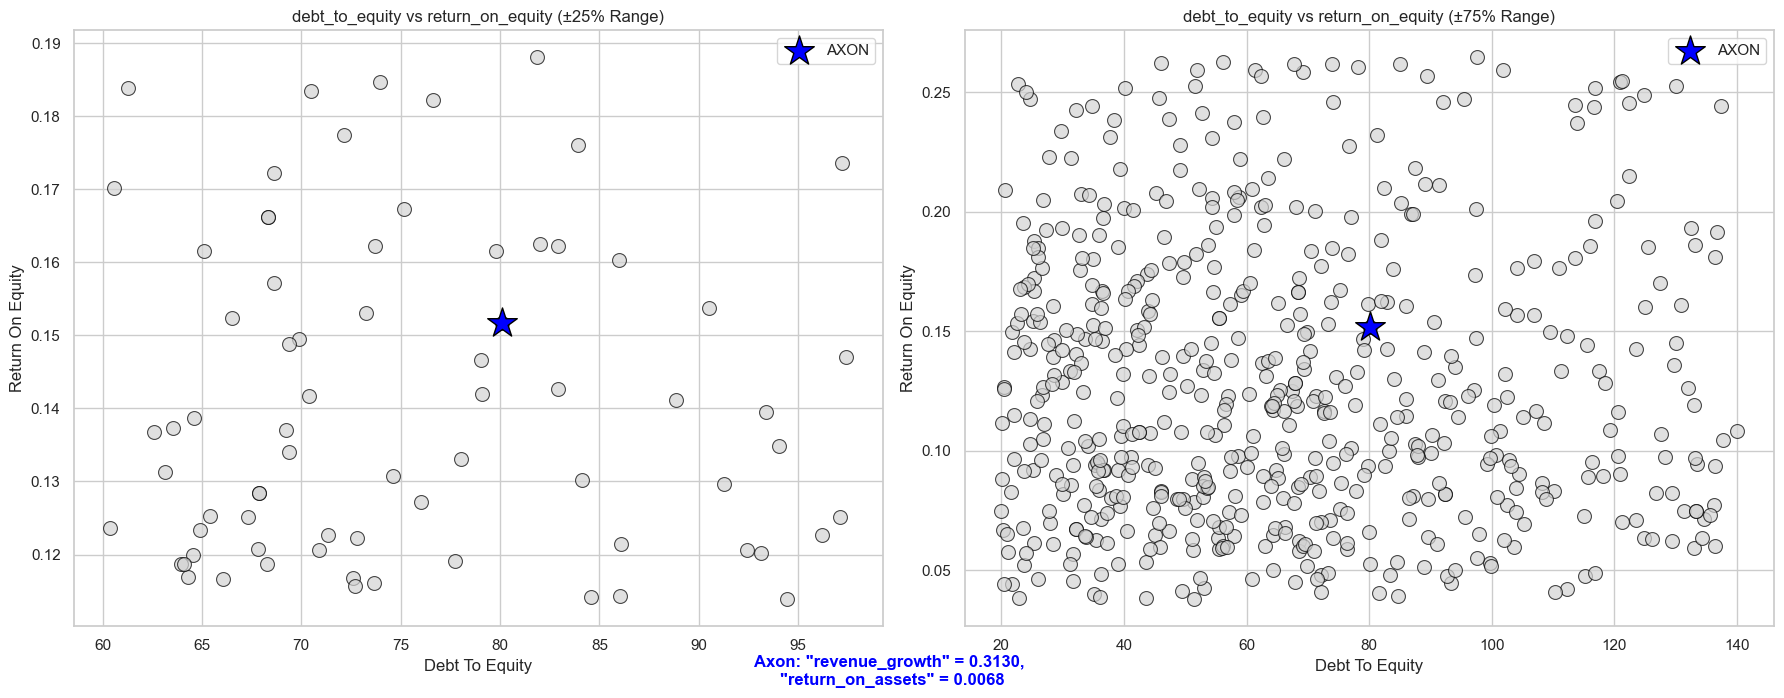

In [6]:
# Lista di combinazioni scatter
scatter_combinations = [
    ('pe_forward', 'return_on_equity'),
    ('price_to_sales','net_profit_margin'),
    ('revenue_growth', 'return_on_assets'),
    ('debt_to_equity','return_on_equity')
]

# Messaggi da stampare dopo ogni coppia
messages = [f'Axon: "pe_forward" = {target_company['pe_forward']:.4f}, \n"return_on_equity" = {target_company['return_on_equity']:.4f}',
            f'Axon: "price_to_sales" = {target_company['price_to_sales']:.4f}, \n"net_profit_margin" = {target_company['net_profit_margin']:.4f}',
            f'Axon: "debt_to_equity" = {target_company['debt_to_equity']:.4f}, \n"return_on_equity" = {target_company['return_on_equity']:.4f}',
            f'Axon: "revenue_growth" = {target_company['revenue_growth']:.4f}, \n"return_on_assets" = {target_company['return_on_assets']:.4f}']

    
def plot_two_scatter(metric_x, metric_y, message=''):
    x_val = target_company[metric_x]
    y_val = target_company[metric_y]

    # Setup figura con 2 subplot affiancati
    fig, axes = plt.subplots(1, 2, figsize=(18, 7)) 

    # Primo filtro: ±25%
    x_low1, x_high1 = x_val * 0.75, x_val * 1.25
    y_low1, y_high1 = y_val * 0.75, y_val * 1.25

    filtered_df1 = metrics_df[
        metrics_df[metric_x].between(x_low1, x_high1) &
        metrics_df[metric_y].between(y_low1, y_high1)
    ]

    sns.scatterplot(
        data=filtered_df1,
        x=metric_x,
        y=metric_y,
        color ='lightgray',
        alpha=0.7,
        s=100,
        edgecolor='black',
        ax=axes[0]
    )
    axes[0].scatter(
        x_val, y_val,
        color='blue',
        s=500,
        marker='*',
        label='AXON',
        edgecolor='black',
        zorder=5
    )
    axes[0].set_title(f"{metric_x} vs {metric_y} (±25% Range)")
    axes[0].set_xlabel(metric_x.replace('_', ' ').title())
    axes[0].set_ylabel(metric_y.replace('_', ' ').title())
    axes[0].legend()

    # Secondo filtro: ±75% (0.25 - 1.75)
    x_low2, x_high2 = x_val * 0.25, x_val * 1.75
    y_low2, y_high2 = y_val * 0.25, y_val * 1.75

    filtered_df2 = metrics_df[
        metrics_df[metric_x].between(x_low2, x_high2) &
        metrics_df[metric_y].between(y_low2, y_high2)
    ]
    
    sns.scatterplot(
        data=filtered_df2,
        x=metric_x,
        y=metric_y,
        color='lightgray',
        alpha=0.7,
        s=100,
        edgecolor='black',
        ax=axes[1]
    )
    axes[1].scatter(
        x_val, y_val,
        color='blue',
        s=500,
        marker='*',
        label='AXON',
        edgecolor='black',
        zorder=5
    )
    axes[1].set_title(f"{metric_x} vs {metric_y} (±75% Range)")
    axes[1].set_xlabel(metric_x.replace('_', ' ').title())
    axes[1].set_ylabel(metric_y.replace('_', ' ').title())
    axes[1].legend()

    fig.text(0.5, 0.01, message, ha='center', fontsize=12, fontweight = 'bold', color = "blue")


    plt.tight_layout()
    plt.show()

# Usa questa funzione per ogni combinazione
for i, (metric_x, metric_y) in enumerate(scatter_combinations):
    plot_two_scatter(metric_x, metric_y, message=messages[i])

<h4 style="margin:0; line-height:1.2; font-size:26px;">

When the range is **expanded to ±75%**, the scatterplots become more populated and informative. In the first three comparisons:

- **PE Forward** vs **Return on Equity**
- **Price to Sales** vs **Net Profit Margin**
- **Revenue Growth** vs **Return on Assets**

AXON remains distinctly positioned on the far right of each plot, while all other companies cluster to the left. This suggests that AXON consistently has higher values for the horizontal-axis variables (PE Forward, Price to Sales, and Revenue Growth). While it’s not always highest vertically (i.e., in profitability), its separation from peers remains evident, confirming its status as a performance outlier in terms of valuation and growth.

In the final scatterplot:
- **Debt to Equity** vs **Return on Equity**

The distribution remains very similar to the 25% range scenario, but with more companies now visible. AXON continues to sit in the middle of the cluster, reinforcing that its leverage and return on equity metrics are close to industry averages and do not significantly differentiate it from its peers.

<h4 style="margin:0; line-height:1.2; font-size:28px;">

Summary Insight

<h4 style="margin:1; line-height:1.2; font-size:22px;">

This visual analysis confirms that **AXON distinguishes itself** mainly for profitability, valuation, and growth metrics, while its capital structure (debt levels) aligns more **closely** with the **industry average**.